# 03 — Causal design and identification

**Project:** Chess clock increment and the probability of losing on time  
**Source:** January 2013 Lichess rated standard games  
**This notebook specifies the research design; it does not fit a treatment-effect model.**

**Primary policies:** `120+0` vs `120+2`; `180+0` vs `180+2`; `300+0` vs `300+2`.  
**Secondary comparison:** `300+0` vs `300+5`.

We distinguish (a) the effect of choosing a time-control **queue before matchmaking** from (b) a hypothetical effect of changing the clock **while holding the players/opponent fixed**. The observational data cannot identify either without additional assumptions.

## 1. Load and validate the study cohort

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if not (root / "data" / "processed" / "increment_player_games.csv").exists():
    root = root.parent
path = root / "data" / "processed" / "increment_player_games.csv"
assert path.exists(), f"Dataset not found: {path}"
pg = pd.read_csv(path, parse_dates=["started_at_utc"])
required = {"game_id", "player", "opponent", "initial_seconds", "increment_seconds",
            "time_control", "player_elo", "opponent_elo", "color", "lost_on_time", "started_at_utc"}
assert required.issubset(pg.columns), required - set(pg.columns)
assert pg.groupby("game_id").size().eq(2).all()
assert pg["lost_on_time"].isin([0, 1]).all()

bases = (120, 180, 300)
primary = pg.loc[
    pg["initial_seconds"].isin(bases) & pg["increment_seconds"].isin([0, 2])
].copy()
primary["treated"] = primary["increment_seconds"].eq(2).astype(int)
assert (primary["has_increment"] == primary["treated"]).all()
print("Primary game count:", primary["game_id"].nunique())
print("Primary player-game observations:", len(primary))
print("Unique players:", primary["player"].nunique())
display(primary.groupby(["initial_seconds", "time_control"]).agg(games=("game_id", "nunique"), player_games=("game_id", "size")).reset_index())

Primary game count: 29762
Primary player-game observations: 59524
Unique players: 2819


,initial_seconds,time_control,games,player_games
0,120,120+0,5950,11900
1,120,120+2,1212,2424
2,180,180+0,8243,16486
3,180,180+2,1194,2388
4,300,300+0,10172,20344
5,300,300+2,2991,5982


## 2. Specify the target trial

| Trial component | Target specification |
|---|---|
| Eligibility | A player about to enter a rated standard Lichess game with starting clock 120, 180, or 300 seconds; conceptually able/willing to enter either available queue |
| Intervention | Select starting-clock `b+2` rather than `b+0`, for a fixed `b` |
| Assignment time (time zero) | **Before entering matchmaking**, not after the game begins |
| Follow-up | Through the outcome of that one game |
| Outcome | `lost_on_time = 1` if the focal player loses a decisive game by time forfeit; 0 otherwise (including draws by time forfeit) |
| Unit | Player-game (two per game); clock policy is common to both players |
| Population | Observed eligible player-game opportunities with empirical treatment overlap; generalization beyond 2013 is not assumed |
| Contrast | Risk difference: +2-second-policy minus no-increment-policy at each starting clock |

**Important:** We do not observe *the same player's queue-entry opportunities under both assignments*. Identifying a treatment effect from completed games assumes selection into a completed game does not induce problematic bias. The time between matchmaking and game outcome is not modeled explicitly.

**Alternative estimand:** A *conditional match-level clock intervention* fixes both players/opponent and changes the clock rule. This may be a clearer physical effect of increment, but the observational games are not randomized conditional on opponent pair, and most exact pairs are not repeatedly observed under both policies. Do not conflate it with the queue-choice effect.

## 3. Define potential outcomes and estimands

For starting clock $b$, let $Y_i(1;b)$ be the indicator that focal player-game opportunity $i$ ends with a loss on time if assigned policy `$b+2` and $Y_i(0;b)$ under `$b+0`.

The stratum-specific average treatment effect (ATE) is

$$\tau_b = E[Y_i(1;b) - Y_i(0;b) \mid B=b, i\in\mathcal P_b], \quad b\in\{120,180,300\}.$$

A negative value would mean lower timeout-loss risk with increment. An optional pooled summary is $\tau_{pool}=\sum_b w_b\tau_b$, using **predeclared** weights $w_b$. We will not pool raw rates across clocks.

We propose weighting strata according to the proportions of **unique games in the current eligible primary cohort** (descriptive target population); uniform weights across strata can be a sensitivity analysis. Such weights do not correct selection into the observational sample. The covariate distribution and target population must be fixed before fitting models.

The term *causal effect* is conditional on assumptions in Sections 4–5 and is not established by EDA.

In [2]:
strata_games = primary.groupby("initial_seconds")["game_id"].nunique().sort_index()
weights = (strata_games / strata_games.sum()).rename("target_weight")
display(pd.concat([strata_games.rename("games"), weights], axis=1))
assert np.isclose(weights.sum(), 1.0)

,games,target_weight
initial_seconds,,
120,7162,0.240642
180,9437,0.317082
300,13163,0.442275


## 4. Causal DAG and timing of variables

The diagram represents the **queue-choice** estimand, not a guaranteed true data-generating process.

```mermaid
flowchart LR
    U[Unmeasured preference / time skill] --> A[Choose increment policy]
    U --> Y[Lose on time]
    R[Pre-game player rating] --> A
    R --> Y
    H[Prior games / recent form] --> A
    H --> Y
    D[UTC hour / calendar date] --> A
    D --> Y
    B[Starting clock, held fixed] --> A
    B --> Y
    A --> M[Opponent selected via matchmaking]
    M --> Y
    A --> Y
```

**Pre-treatment candidates (for the queue-choice effect):** focal player's pre-game rating, past game history *up to time zero*, calendar day and UTC hour (as imperfect environmental proxies), and baseline 120/180/300-second stratum. **Player identity** captures stable observable and unobservable personal attributes.

**Potentially post-treatment:** opponent identity/rating under matchmaking queue choice; moves played, length of game, termination, and rating change. **Do not automatically adjust** for these in the primary total queue-choice effect. Opponent rating is still useful as a separate *opponent-standardized sensitivity analysis* with a different interpretation.

**Practical warning:** We do not observe actual queue-entry timestamps or user time zones. `started_at_utc` can be a proxy for selection conditions, but it may occur after treatment assignment.

## 5. Identification assumptions and limitations

1. **Consistency / well-defined treatment:** All games classified `+2` implement the same per-move 2-second increment. Rule differences aside from increments should be absent or documented. Changing queues also changes matchmaking composition, so a queue policy includes that pathway.
2. **Conditional exchangeability:** Within a starting-clock stratum, conditional on pre-treatment covariates, time-control selection is as good as random with respect to potential outcomes. This is **strong and untestable** here because clock preferences, fatigue, time-management ability, and motivation are not fully observed.
3. **Positivity:** Comparable players must have nonzero probability of choosing each policy. Observing both policies within strata is a start, but individual-level overlap must be assessed.
4. **No interference / stable unit definition:** Players affect each other's time management, and two player records come from the same game. A game-level policy intervention explicitly changes both players' conditions. A player-level potential outcome should be understood for the whole match environment, not as an independent treatment delivered to one opponent only.
5. **Selection into observed games:** Only completed/recorded games are present. If policy affects whether games are initiated, completed, or included, causal inference among observed games may be selected.
6. **Measurement:** `Termination == "Time forfeit"` and decisive `Result` identify recorded losses on time; the data cannot measure near timeouts, remaining clock, or the mechanism of time pressure.

**Interpretation gate:** Because exchangeability is doubtful, any observational estimate should be described as *adjusted association under stated assumptions*, not an established causal effect.

## 6. Diagnostics: stratum-by-policy counts and exact within-player overlap

Counts establish feasibility, **not** exchangeability. Switching across policies may itself be related to recent form or preferences.

In [3]:
counts = primary.groupby(["initial_seconds", "treated"]).agg(
    games=("game_id", "nunique"), players=("player", "nunique"),
    observations=("game_id", "size")
).reset_index()
display(counts)

switch_rows = []
for b, g in primary.groupby("initial_seconds"):
    n_policy = g.groupby("player")["treated"].nunique()
    both = set(n_policy.index[n_policy.eq(2)])
    sw = g[g["player"].isin(both)]
    switch_rows.append({"initial_seconds": b, "switching_players": len(both),
                        "switcher_player_games": len(sw),
                        "switcher_untreated": (sw["treated"] == 0).sum(),
                        "switcher_treated": (sw["treated"] == 1).sum()})
switch_table = pd.DataFrame(switch_rows)
display(switch_table)

,initial_seconds,treated,games,players,observations
0,120,0,5950,1014,11900
1,120,1,1212,472,2424
2,180,0,8243,1654,16486
3,180,1,1194,499,2388
4,300,0,10172,1808,20344
5,300,1,2991,969,5982


,initial_seconds,switching_players,switcher_player_games,switcher_untreated,switcher_treated
0,120,312,7691,5607,2084
1,180,389,9543,7668,1875
2,300,756,18425,13371,5054


## 7. Inspect overlap in *pre-treatment* player rating

Because every game contributes two perspectives, ratings are symmetric across players/opponents at the game level. Rating balance does **not** imply absence of unmeasured confounding.

The boxplots below show distributions; the group summaries help identify severe non-overlap. We avoid using outcome data to pick a convenient subpopulation.

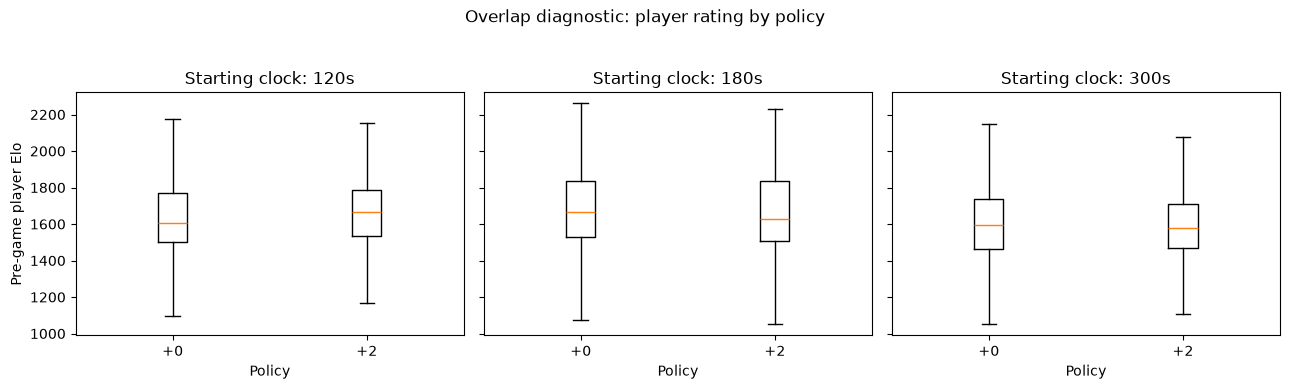

count    mean    std  min  median   max
initial_seconds treated                                         
120             0        11900  1640.6  223.1  968  1605.0  2289
                1         2424  1655.9  200.8  843  1667.0  2275
180             0        16486  1677.5  213.8  856  1667.0  2305
                1         2388  1658.0  206.0  933  1625.0  2230
300             0        20344  1596.8  202.8  858  1596.0  2248
                1         5982  1578.7  180.2  951  1577.0  2146

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.7), sharey=True)
for a, (b, g) in zip(ax, primary.groupby("initial_seconds")):
    a.boxplot([g.loc[g["treated"] == v, "player_elo"].to_numpy() for v in (0, 1)],
              tick_labels=["+0", "+2"], showfliers=False)
    a.set_title(f"Starting clock: {b}s")
    a.set_xlabel("Policy")
ax[0].set_ylabel("Pre-game player Elo")
fig.suptitle("Overlap diagnostic: player rating by policy", y=1.04)
plt.tight_layout()
plt.show()

display(primary.groupby(["initial_seconds", "treated"])["player_elo"].agg(["count", "mean", "std", "min", "median", "max"]).round(1))

## 8. Propensity-overlap *diagnostic only* (no effect estimation)

Fit a simple policy-choice classifier to check whether observed pre-game features separate the queues. This is **not** a causal estimator, and moderate predictive discrimination does not establish exchangeability. We intentionally omit opponent attributes under the pre-matchmaking total-effect interpretation.

The classifier includes rating and UTC hour as an *exploratory proxy*. If time zero precedes recorded game start, UTC hour is not guaranteed strictly pre-treatment; later analyses should compare versions with and without it.

Do not trim or threshold observations based on this exploratory plot before writing a target-population rule. Models are trained separately within each clock stratum; report in-sample propensity distributions as descriptive only.

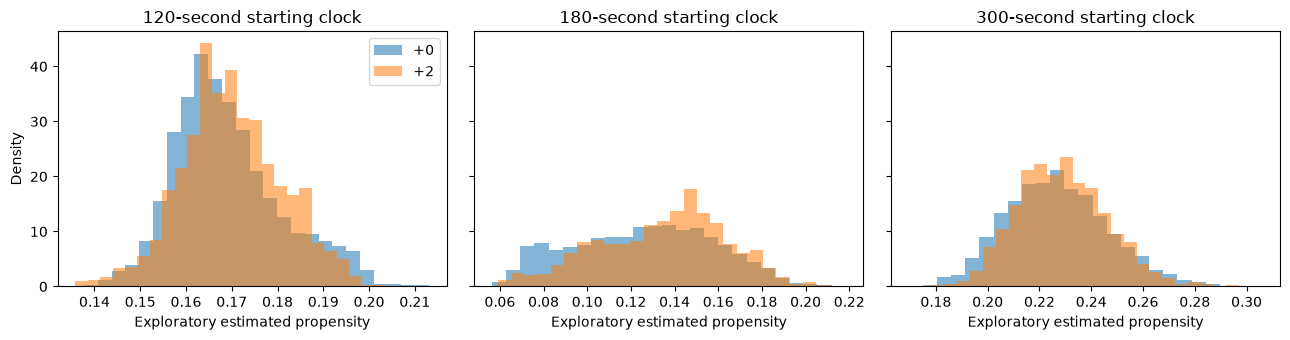

,initial_seconds,share_p_below_0_05,share_p_above_0_95,min_estimated_p,max_estimated_p
0,120,0.0,0.0,0.136,0.213
1,180,0.0,0.0,0.056,0.218
2,300,0.0,0.0,0.169,0.306


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

primary["utc_hour"] = primary["started_at_utc"].dt.hour
propensity_diagnostics = []
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (b, g) in zip(axes, primary.groupby("initial_seconds")):
    x = g[["player_elo", "utc_hour"]].copy()
    y = g["treated"].astype(int)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
    model.fit(x, y)
    p = model.predict_proba(x)[:, 1]
    for t, label in [(0, "+0"), (1, "+2")]:
        ax.hist(p[y.to_numpy() == t], bins=25, alpha=.55, density=True, label=label)
    ax.set_title(f"{b}-second starting clock")
    ax.set_xlabel("Exploratory estimated propensity")
    propensity_diagnostics.append({"initial_seconds": b,
        "share_p_below_0_05": float((p < .05).mean()),
        "share_p_above_0_95": float((p > .95).mean()),
        "min_estimated_p": float(p.min()), "max_estimated_p": float(p.max())})
axes[0].set_ylabel("Density")
axes[0].legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame(propensity_diagnostics).round(3))

## 9. Repeated players, opponents, and dependent records

The policy is at **game level**. The two player-game rows are intrinsically dependent, and the same player can return across games (including as opponents). Simple row-level heteroskedastic-robust errors or one-way clustering **only by game** would miss repeated-player dependence.

Possible inference strategy for later modeling: cluster-aware bootstrap of games with explicit player-network dependence checks; game-level analysis of whether a game had a decisive timeout (one record per game) is a useful separate estimand; or use an appropriate multiway/network-robust method if implemented and justified. No single off-the-shelf cluster label fully solves dependence through both players and games. We'll choose and verify an inference method in the estimation notebook.

The next table measures this dependence structure.

In [6]:
player_counts = primary.groupby("player").size().sort_values(ascending=False)
pair_games = primary[["game_id", "player", "opponent"]].drop_duplicates("game_id")
print("Player-game rows:", len(primary))
print("Games:", primary["game_id"].nunique())
print("Unique players:", primary["player"].nunique())
print("Players with more than one observation:", int((player_counts > 1).sum()))
print("Top 10 players' share of player-game observations:", f"{player_counts.head(10).sum()/len(primary):.2%}")
print("Unique first-seen opponent pairs:", len(pair_games))
display(player_counts.describe(percentiles=[.5, .75, .9, .95, .99]).to_frame("player_games"))

Player-game rows: 59524
Games: 29762
Unique players: 2819
Players with more than one observation: 2142
Top 10 players' share of player-game observations: 10.50%
Unique first-seen opponent pairs: 29762


,player_games
count,2819.000000
mean,21.115289
std,56.645416
min,1.000000
50%,4.000000
75%,15.000000
90%,49.000000
95%,98.100000
99%,246.460000
max,1017.000000


## 10. Primary versus secondary policies

The secondary policy comparison (`300+0` versus `300+5`) answers a **distinct contrast**. Comparing its estimated effect with `300+2` would *not* automatically identify an increment dose-response curve because populations choosing different increments may differ.

Use these numbers only to assess sample size and switching feasibility; don't select the primary comparison because its observed treatment effect looks larger.

In [7]:
secondary = pg.loc[pg["time_control"].isin(["300+0", "300+5"])].copy()
secondary["treated"] = secondary["increment_seconds"].eq(5).astype(int)
sc = secondary.groupby("time_control").agg(games=("game_id", "nunique"), players=("player", "nunique"))
display(sc)
secondary_switchers = secondary.groupby("player")["treated"].nunique().eq(2).sum()
print("Players playing both secondary policies:", secondary_switchers)

,games,players
time_control,,
300+0,10172,1808
300+5,4307,1175


Players playing both secondary policies: 854


### Diagnostic Findings and Final Design Decisions

**1. Evidence for / against practical positivity**

The exploratory propensity-score model found no estimated probabilities below 0.05 or above 0.95 across the three starting-clock strata.

Estimated probabilities ranged from 0.136–0.213 for 120-second games, 0.056–0.218 for 180-second games, and 0.169–0.306 for 300-second games.

This suggests adequate overlap in the observed player Elo and UTC-hour characteristics included in the model. The rating distributions also show substantial overlap between treatment groups.

However, practical positivity cannot be established from these diagnostics alone. The model excludes important determinants of time-control selection, including player preferences and prior behavior. Furthermore, some players may strongly prefer one policy despite the apparent overlap in observed characteristics.

**Decision:** Retain all three starting-clock strata for the initial analysis. Reassess overlap after specifying the final adjustment model, rather than restricting the sample based solely on this exploratory propensity model.

**2. Which starting clock has the best switching-player support, and why?**

The 300-second stratum has the strongest switching-player support in absolute terms.

It contains 756 players who participated in both `300+0` and `300+2` games, contributing 18,425 player-game observations. Of these, 13,371 observations were from non-increment games and 5,054 from increment games.

In comparison, the 120-second stratum contains 312 switching players and the 180-second stratum contains 389.

The 300-second stratum therefore provides the largest observed sample for a within-player comparison. Nevertheless, its greater sample size does not guarantee that the resulting estimates will have less bias.

**Decision:** Retain all three strata in the primary analysis, while considering 300-second games as a particularly informative stratum for within-player sensitivity analyses.

**3. Which covariates should be in the main model versus sensitivity models?**

The primary analysis will target the total effect of selecting an increment queue before matchmaking.

The main adjustment model will include pre-game focal-player Elo and starting-clock strata, with effects estimated separately for each starting-clock duration. Calendar and UTC-hour variables will be examined as potential proxies for game-selection conditions, with attention to their timing relative to queue choice.

Sensitivity analyses will include:

- Player fixed effects among players observed under both policies.
- Opponent-rating adjustment to examine an opponent-standardized association rather than the total queue-choice effect.
- Alternative specifications including or excluding calendar and UTC-hour variables.
- Analyses limiting the influence of extremely active players.
- The secondary `300+5` versus `300+0` comparison.

Post-treatment variables, including number of moves, game duration, termination type, and post-game rating changes, will not be used as adjustment variables in the primary outcome model.

**Decision:** Prioritize covariates plausibly measured before treatment assignment, and distinguish the total queue-choice effect from analyses that condition on matchmaking outcomes.

**4. What remains unidentified by these observational games?**

The dataset does not directly identify the causal effect of increment availability because players voluntarily select time controls.

Unmeasured factors such as time-management ability, motivation, fatigue, and playing preferences may affect both treatment selection and timeout risk.

Additionally, changing the time-control queue may change the opponent encountered. Consequently, the effect of queue selection cannot automatically be interpreted as the effect of adding two seconds to an otherwise identical game.

The dataset also contains only recorded games, does not observe queue-entry decisions or exact player time zones, and includes repeated observations from interconnected players.

**Decision:** Interpret subsequent estimates as adjusted observational associations unless the necessary identification assumptions can be justified. Report uncertainty intervals and sensitivity analyses, and avoid claiming that increment availability has been proven to cause a reduction in timeout losses.

**Estimation notebook plan (`04_causal_estimation.ipynb`):** establish models and uncertainty method, report risk differences with interval estimates, compare balance where weighting is used, and document assumptions alongside all results.